In [1]:
import pandas as pd

# 1) Relire le dataset créé dans le notebook 1
df = pd.read_csv("donnees_irrigation.csv")
print("Dataset chargé :", df.shape)

# 2) Séparer les ENTRÉES (X) et la SORTIE (y)
X = df[["temperature", "humidite_air", "humidite_sol", "ph", "luminosite"]]   # les 5 capteurs
y = df["irrigation"]                                                          # la réponse : 0 ou 1

print("X (entrées) :", X.shape)
print("y (sortie)  :", y.shape)
X.head()

Dataset chargé : (5000, 6)
X (entrées) : (5000, 5)
y (sortie)  : (5000,)


,temperature,humidite_air,humidite_sol,ph,luminosite
0,36.0,36.4,72,5.7,74
1,22.6,69.7,71,4.5,100
2,39.3,77.5,20,5.5,4
3,32.9,32.5,4,8.0,24
4,8.8,23.3,30,6.5,60


In [2]:
from sklearn.model_selection import train_test_split

# Couper en 80 % entraînement / 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20 % pour le test
    random_state=42,    # même découpage à chaque exécution
    stratify=y          # garder la même proportion de 0 et de 1 dans les deux groupes
)

print("Entraînement :", X_train.shape[0], "lignes")
print("Test         :", X_test.shape[0], "lignes")
print()
print("Proportion de 'arroser' (1) :")
print("  dans l'entraînement :", round(y_train.mean() * 100, 1), "%")
print("  dans le test        :", round(y_test.mean() * 100, 1), "%")

Entraînement : 4000 lignes
Test         : 1000 lignes

Proportion de 'arroser' (1) :
  dans l'entraînement : 45.4 %
  dans le test        : 45.4 %


In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 1) Les 4 modèles à comparer
modeles = {
    "Arbre de décision":     DecisionTreeClassifier(max_depth=6, random_state=42),
    "KNN":                   make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Random Forest":         RandomForestClassifier(n_estimators=200, random_state=42),
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression()),
}

# 2) Pour chaque modèle : apprendre, puis passer l'examen
resultats = []
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)            # APPRENDRE sur les 4 000 lignes d'entraînement
    predictions = modele.predict(X_test)    # RÉPONDRE aux 1 000 questions de l'examen
    note = accuracy_score(y_test, predictions)   # % de bonnes réponses
    resultats.append({"Modèle": nom, "Accuracy (%)": round(note * 100, 1)})
    print(f"{nom:<22} -> {note*100:.1f} % de bonnes réponses")

# 3) Tableau récapitulatif, du meilleur au moins bon
tableau = pd.DataFrame(resultats).sort_values("Accuracy (%)", ascending=False)
tableau

Arbre de décision      -> 92.8 % de bonnes réponses
KNN                    -> 94.0 % de bonnes réponses
Random Forest          -> 93.7 % de bonnes réponses
Régression logistique  -> 95.5 % de bonnes réponses


,Modèle,Accuracy (%)
3,Régression logistique,95.5
1,KNN,94.0
2,Random Forest,93.7
0,Arbre de décision,92.8


Meilleur modèle : Régression logistique

                    precision    recall  f1-score   support

Ne pas arroser (0)       0.97      0.95      0.96       546
       Arroser (1)       0.94      0.96      0.95       454

          accuracy                           0.95      1000
         macro avg       0.95      0.96      0.95      1000
      weighted avg       0.96      0.95      0.96      1000



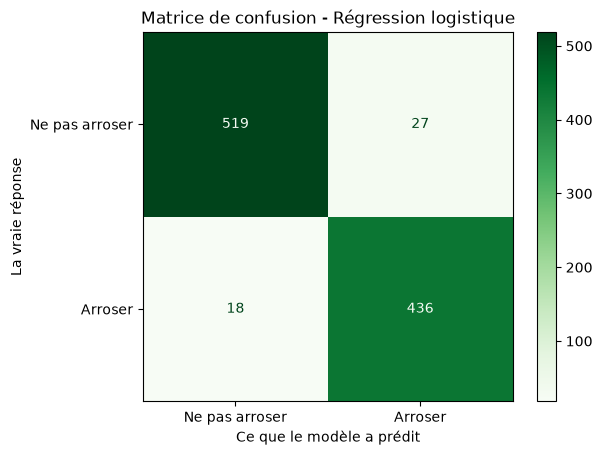

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Le meilleur modèle
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur = modeles[meilleur_nom]
predictions = meilleur.predict(X_test)

print("Meilleur modèle :", meilleur_nom)
print()
print(classification_report(y_test, predictions,
                            target_names=["Ne pas arroser (0)", "Arroser (1)"]))

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    display_labels=["Ne pas arroser", "Arroser"],
    cmap="Greens"
)
plt.title(f"Matrice de confusion - {meilleur_nom}")
plt.xlabel("Ce que le modèle a prédit")
plt.ylabel("La vraie réponse")
plt.show()

In [5]:
import joblib

# 1) Sauvegarder le meilleur modèle dans un fichier
joblib.dump(meilleur, "modele_irrigation.joblib")
print("Modèle sauvegardé :", meilleur_nom)

# 2) Le recharger, comme le fera le serveur, et le tester sur 2 situations inventées
modele_charge = joblib.load("modele_irrigation.joblib")

situations = pd.DataFrame([
    {"temperature": 38, "humidite_air": 30, "humidite_sol": 22, "ph": 6.5, "luminosite": 90},  # été, sol sec
    {"temperature": 18, "humidite_air": 80, "humidite_sol": 65, "ph": 7.0, "luminosite": 10},  # nuit fraîche, sol humide
])

decisions = modele_charge.predict(situations)
probas    = modele_charge.predict_proba(situations)[:, 1]   # probabilité d'arroser

for i in range(len(situations)):
    print(f"Situation {i+1} -> {'ARROSER' if decisions[i] == 1 else 'NE PAS ARROSER'}"
          f"  (certitude d'arroser : {probas[i]*100:.0f} %)")

Modèle sauvegardé : Régression logistique
Situation 1 -> ARROSER  (certitude d'arroser : 100 %)
Situation 2 -> NE PAS ARROSER  (certitude d'arroser : 0 %)
